Script to automatically align volumetric scape data to a muscle reference map by using the accessory heart muscles.

Requires first manually labelled the accessory heart muscles in the scape video. Note: do this when the muscle is lit up but not when it is contracted, as it distorts its shape.

Steps:
- Load manual rois 
- Load max projection for matching data
- asign manual rois an identity (RF, LF, etc.) - remember right is on left when looking at legs
- Load reference labels (for acc-heart-muscles but also all selected muscles)
- get centroid of both manual and referece
- scale, rotate and shift reference to match manual - how does it look? Compare selected muscles to max projection
- if not great, try stretching

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from scape_utils import load_napari_rois, load_aspect_ratio_YX, load_proj

import sys
sys.path.append(str(Path('/home/azcorra/git/Devel/Pupa_muscle_imaging/referenceMaps')))
from webknossos import load_labels

In [12]:
# set paths to data and reference map labels:
main_path = Path('/mnt/labserver/data/MA/SCAPE/')
scape_path = main_path / '20260716_MA12_pupa-P15/sample2_run2'
acc_heart_path = scape_path / 'accessory_heart_muscles_rois.nrrd'

reference_path = Path('/mnt/labserver/data/MA/CT_scans_PIXE/2026-06-16_Webknossos_muscle_leg_tracing_pupa_annotations/Front Right Leg muscles in pupa')
labels_path = reference_path / 'Labels'
selected_path = reference_path / 'meshes-selected'

In [3]:
# Get std image for scape data (and aspect_ratio for plotting)
std = load_proj(scape_path, 'std_image')
aspect_ratio_YX = load_aspect_ratio_YX(scape_path)

In [33]:
# Load manual rois for accessory heart muscles (labels)
acc_heart_manual = load_napari_rois(acc_heart_path)
acc_heart_manual_id = {'RM': 1, 'RF': 2, 'LF': 3, 'LM': 4}

In [34]:
# Load reference labels
labels, id_to_name = load_labels(labels_path) # takes about 2 min
# select accessory heart muscles and match indexes to manual_rois
acc_heart_ids = {name[:2]: id for id, name in id_to_name.items() if 'heart' in name and 'p1' in name}
acc_heart_ref = np.zeros_like(labels, dtype=np.uint8)
for leg, id in acc_heart_ids.items():
    acc_heart_ref[labels == id] = acc_heart_manual_id[leg]
# find the selected muscles (all files in the selected_path folder)
stl_list = list(selected_path.glob('*.stl'))
selected_muscles = {k: v for k, v in (p.stem.rsplit('-', 1) for p in stl_list)}


# TESTING / PLOTTING

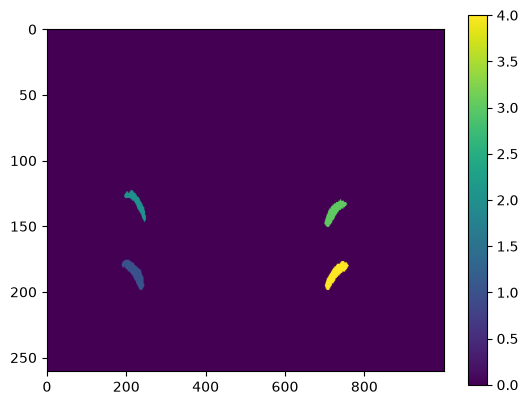

In [18]:
temp = np.max(acc_heart_rois, axis=(0))
plt.imshow(temp, aspect=aspect_ratio_YX)
plt.colorbar()

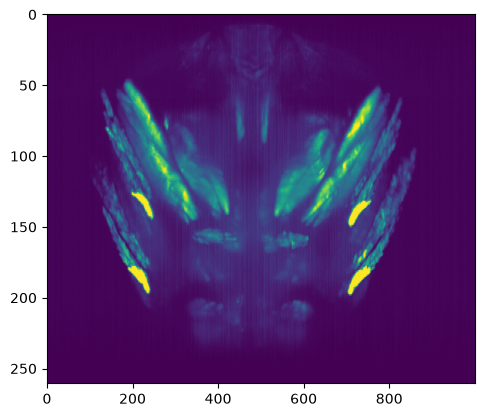

In [19]:

plt.imshow(np.percentile(std, 99, axis=0), aspect=aspect_ratio_YX, vmin=5, vmax=60)

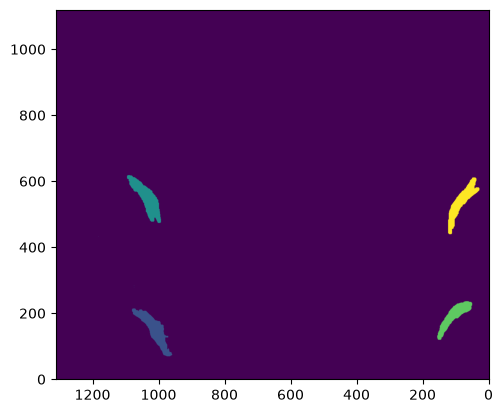

In [30]:
plt.imshow(np.max(acc_heart_ref, axis=(1)).T)
# y-axis inverted
plt.gca().invert_yaxis()
plt.gca().invert_xaxis()